# **Dataset *Sleep Health and Lifestyle***

Nama: Zafira Ryani Putri

NIM: J0403241139

Kelas: TPL 61 B/P2

Mata Kuliah: Analisis dan Visualisasi Data

## **1. Mengumpulkan Data**
**Tujuan:** Mengumpulkan dan memuat dataset yang akan digunakan untuk analisis.

**Deskripsi Dataset:**
Dataset yang digunakan dalam analisis ini adalah *"Sleep Health and Lifestyle"* (Kesehatan Tidur dan Gaya Hidup). Dataset ini berfokus pada metrik kesehatan dan kebiasaan sehari-hari untuk melihat dampaknya terhadap kualitas tidur seseorang. Dataset ini terdiri dari 13 atribut:
- ***Person ID:*** Nomor urut identitas unik untuk setiap individu dalam survei.
- **Jenis Kelamin (*Gender*):** Kategori jenis kelamin responden (*Male/Female*).
- **Usia (*Age*):** Umur responden dalam hitungan tahun.
- **Profesi (*Occupation*):** Pekerjaan atau bidang karier yang ditekuni oleh responden (misal: *Software Engineer*, Doctor, dll).
- **Durasi Tidur (*Sleep Duration*):** Total waktu tidur yang dihabiskan responden per hari (dalam jam).
- **Kualitas Tidur (*Quality of Sleep*):** Penilaian subjektif terhadap seberapa baik kualitas tidur responden, diukur dalam skala 1 hingga 10.
- **Gangguan Tidur (*Sleep Disorder*):** Kondisi medis terkait tidur yang dialami responden, seperti Insomnia, Sleep Apnea, atau '*None*' jika tidak memiliki gangguan.
- **Tingkat Stres (*Stress Level*):** Penilaian subjektif terhadap tingkat stres yang dialami responden sehari-hari, diukur dalam skala 1 hingga 10.
- **Tingkat Aktivitas Fisik (*Physical Activity Level*):** Durasi waktu yang dihabiskan responden untuk aktivitas fisik setiap harinya (dalam menit).
- **Jumlah Langkah Harian (*Daily Steps*):** Total langkah kaki yang dicapai responden dalam satu hari.
- **Kategori BMI *(BMI Category*):** Klasifikasi Indeks Massa Tubuh responden yang menunjukkan status berat badan (misal: Normal, *Overweight, Obese*).
- **Tekanan Darah (*Blood Pressure*):** Ukuran tekanan darah responden yang dicatat sebagai nilai Sistolik/Diastolik (contoh: 120/80).
- **Detak Jantung (*Heart Rate*):** Rata-rata detak jantung istirahat responden per menit (bpm).

In [118]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
url = 'https://raw.githubusercontent.com/Lehonci/dataset-uts-anavida/refs/heads/main/Sleep_health_and_lifestyle_dataset.csv'
df_raw = pd.read_csv(url)
df = df_raw.copy()

## **2. Menelaah Data**
**Tujuan:** Mengetahui karakteristik awal data, mencakup tipe data tiap kolom, ringkasan statistik, dan melihat sebaran data secara visual.

In [119]:
# Mengecek struktur baris, kolom, dan tipe data (objek/numerik)
print("Informasi Dataset:")
df.info()

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


Berdasarkan pengecekan menggunakan fungsi `df.info()`, dataset terdiri dari 374 baris data dan 13 kolom variabel. Variabel yang terdapat dalam dataset memiliki beberapa tipe data, yaitu 7 kolom bertipe integer (*int64*), 1 kolom bertipe desimal (*float64*), dan 5 kolom bertipe object yang umumnya berisi data kategorikal seperti *Gender, Occupation,* dan *BMI Category.*

Dari segi kelengkapan data, hampir seluruh kolom tidak memiliki *missing value*, yang ditandai dengan jumlah *non-null* sebanyak 374. Namun, terdapat pengecualian pada kolom *Sleep Disorder* yang hanya memiliki 155 data terisi, sehingga terdapat 219 data yang kosong. Hal ini menunjukkan bahwa variabel tersebut memerlukan penanganan lebih lanjut sebelum digunakan dalam proses analisis atau pemodelan.

In [120]:
# Menampilkan 5 data teratas dataset
display(df.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Fungsi `df.head()` menampilkan lima baris pertama dari dataset *Sleep Health and Lifestyle*. Tujuan pemanggilan fungsi ini adalah untuk mendapatkan gambaran awal mengenai struktur dan isi data sebelum melakukan analisis lebih lanjut. Terlihat bahwa dataset memuat tipe data yang beragam, baik numerik maupun kategorikal. Selain itu, pada kolom `Sleep Disorder` ditemukan nilai `NaN` (*Not a Number*), yang mengindikasikan adanya data kosong.

In [121]:
# Menampilkan ringkasan statistik (rata-rata, min, max, kuartil)
print("\nStatistik Deskriptif:")
display(df.describe(include='all'))


Statistik Deskriptif:


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
count,374.000000,374,374.000000,374,374.000000,374.000000,374.000000,374.000000,374,374,374.000000,374.000000,155
unique,NaN,2,NaN,11,NaN,NaN,NaN,NaN,4,25,NaN,NaN,2
top,NaN,Male,NaN,Nurse,NaN,NaN,NaN,NaN,Normal,130/85,NaN,NaN,Sleep Apnea
freq,NaN,189,NaN,73,NaN,NaN,NaN,NaN,195,99,NaN,NaN,78
mean,187.500000,NaN,42.184492,NaN,7.132086,7.312834,59.171123,5.385027,NaN,NaN,70.165775,6816.844920,NaN
std,108.108742,NaN,8.673133,NaN,0.795657,1.196956,20.830804,1.774526,NaN,NaN,4.135676,1617.915679,NaN
min,1.000000,NaN,27.000000,NaN,5.800000,4.000000,30.000000,3.000000,NaN,NaN,65.000000,3000.000000,NaN
25%,94.250000,NaN,35.250000,NaN,6.400000,6.000000,45.000000,4.000000,NaN,NaN,68.000000,5600.000000,NaN
50%,187.500000,NaN,43.000000,NaN,7.200000,7.000000,60.000000,5.000000,NaN,NaN,70.000000,7000.000000,NaN
75%,280.750000,NaN,50.000000,NaN,7.800000,8.000000,75.000000,7.000000,NaN,NaN,72.000000,8000.000000,NaN


Hasil *output* dari fungsi `.describe(include='all')` memberikan gambaran umum mengenai karakteristik data, baik numerik maupun kategorikal. Dataset terdiri dari 374 responden dengan rata-rata usia sekitar 42 tahun dan distribusi gender yang relatif seimbang, meskipun sedikit didominasi oleh laki-laki. Terdapat 11 jenis pekerjaan, dengan profesi perawat (*Nurse*) sebagai yang paling banyak muncul.

Dari sisi pola tidur, rata-rata durasi tidur responden adalah 7,13 jam per malam dengan kualitas tidur rata-rata sebesar 7,31 yang menunjukkan bahwa mayoritas responden memiliki kualitas tidur yang cukup baik. Tingkat stres berada pada level menengah dengan rata-rata 5,38, sementara aktivitas fisik menunjukkan rata-rata 6.816 langkah per hari.

Dari aspek kesehatan, sebagian besar responden memiliki kategori BMI normal, serta variasi tekanan darah yang cukup beragam, dengan nilai 130/85 sebagai yang paling sering muncul. Selain itu, pada data gangguan tidur yang tersedia, *Sleep Apnea* menjadi kondisi yang paling dominan. Secara keseluruhan, data menunjukkan kondisi responden yang relatif sehat dengan variasi pada tingkat stres dan aktivitas harian.

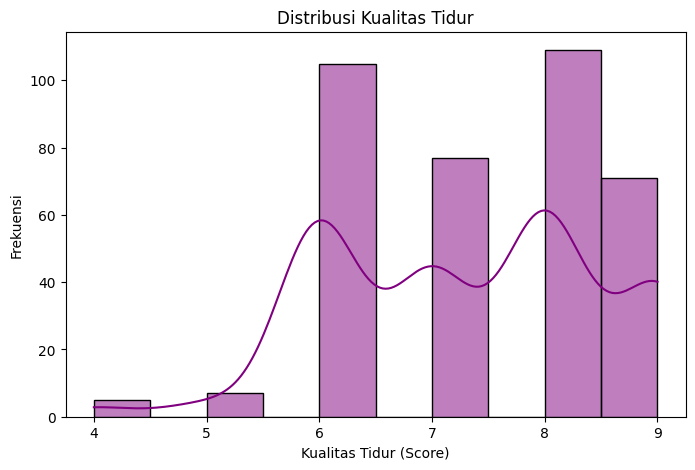

In [122]:
# Visualisasi Distribusi Kualitas Tidur (Target)
plt.figure(figsize=(8, 5))
sns.histplot(df['Quality of Sleep'], bins=10, kde=True, color='purple')
plt.title('Distribusi Kualitas Tidur')
plt.xlabel('Kualitas Tidur (Score)')
plt.ylabel('Frekuensi')
plt.show()

Histogram pada variabel *Quality of Sleep* menunjukkan bahwa distribusi kualitas tidur responden cenderung terkonsentrasi pada nilai menengah hingga tinggi, khususnya pada rentang skor 6 hingga 9. Terlihat bahwa frekuensi tertinggi berada di sekitar nilai 6 dan 8, yang menandakan sebagian besar individu memiliki kualitas tidur yang cukup baik. Sementara itu, nilai rendah seperti 4 dan 5 hanya muncul dalam jumlah yang sangat sedikit, sehingga dapat dianggap sebagai kasus minoritas. Pola kurva menunjukkan distribusi yang tidak sepenuhnya simetris dan cenderung memiliki beberapa puncak (multimodal) yang mengindikasikan adanya variasi kelompok dalam kualitas tidur. Secara keseluruhan, distribusi ini menunjukkan bahwa data didominasi oleh responden dengan kualitas tidur yang relatif baik, dan tidak ditemukan outlier ekstrem yang signifikan.

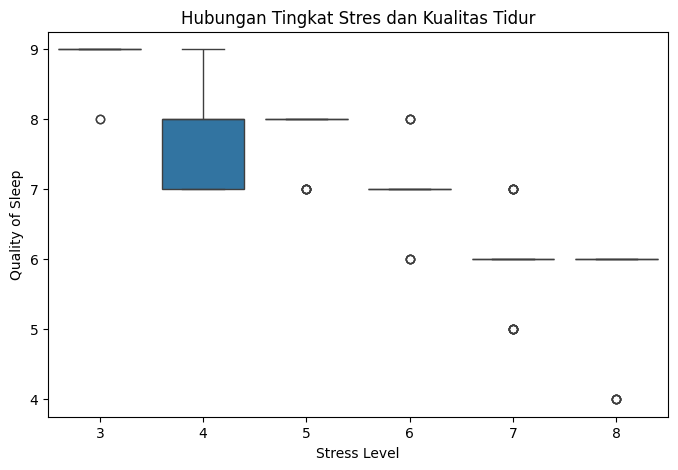

In [123]:
# Visualisasi Hubungan Tingkat Stres dan Kualitas Tidur
plt.figure(figsize=(8, 5))
sns.boxplot(x='Stress Level', y='Quality of Sleep', data=df)
plt.title('Hubungan Tingkat Stres dan Kualitas Tidur')
plt.show()

Dari grafik terlihat bahwa individu dengan tingkat stres yang lebih rendah (sekitar 3–4) cenderung memiliki kualitas tidur yang lebih tinggi, berada pada kisaran skor 7 hingga 9. Sebaliknya, pada tingkat stres yang lebih tinggi (sekitar 6–8), kualitas tidur cenderung menurun dan lebih bervariasi, bahkan terdapat beberapa nilai yang berada pada skor rendah seperti 4 dan 5.

Selain itu, sebaran data pada tingkat stres menengah hingga tinggi terlihat lebih menyebar, yang menunjukkan bahwa semakin tinggi stres seseorang, kualitas tidurnya menjadi semakin tidak konsisten. Pola ini mengindikasikan bahwa stres merupakan salah satu faktor yang berpengaruh terhadap penurunan kualitas tidur, meskipun tidak sepenuhnya linier karena masih terdapat beberapa individu dengan stres tinggi namun kualitas tidur yang cukup baik. Secara keseluruhan, grafik ini memperkuat asumsi bahwa peningkatan tingkat stres cenderung berdampak negatif terhadap kualitas tidur.

## **3. Memvalidasi Data**
**Tujuan:** Memastikan data valid, tidak ada duplikasi yang merusak model, dan nilai-nilainya masuk akal (konsisten).

In [124]:
# 1. Mengecek missing values
print("Jumlah missing value tiap kolom:")
print(df.isna().sum())

# 2. Mengecek duplikasi data
jumlah_duplikat = df.duplicated().sum()
print(f"\nJumlah baris duplikat: {jumlah_duplikat}")

# 3. Mengecek nilai tidak logis (durasi tidur negatif)
invalid_sleep = df[df['Sleep Duration'] < 0]
print(f"Jumlah data dengan durasi tidur negatif: {len(invalid_sleep)}")

# 4. Mengecek nilai tidak logis (durasi tidur > 24 jam)
invalid_sleep_max = df[df['Sleep Duration'] > 24]
print(f"Jumlah data dengan durasi tidur > 24 jam: {len(invalid_sleep_max)}")

# 5. Validasi rentang Quality of Sleep (harusnya 1–10)
invalid_quality = df[(df['Quality of Sleep'] < 1) | (df['Quality of Sleep'] > 10)]
print(f"Jumlah data dengan kualitas tidur tidak valid: {len(invalid_quality)}")

# 6. Validasi Stress Level (harusnya 1–10)
invalid_stress = df[(df['Stress Level'] < 1) | (df['Stress Level'] > 10)]
print(f"Jumlah data dengan stress level tidak valid: {len(invalid_stress)}")

# 7. Validasi nilai langkah harian (tidak boleh negatif)
invalid_steps = df[df['Daily Steps'] < 0]
print(f"Jumlah data dengan langkah harian negatif: {len(invalid_steps)}")

Jumlah missing value tiap kolom:
Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64

Jumlah baris duplikat: 0
Jumlah data dengan durasi tidur negatif: 0
Jumlah data dengan durasi tidur > 24 jam: 0
Jumlah data dengan kualitas tidur tidak valid: 0
Jumlah data dengan stress level tidak valid: 0
Jumlah data dengan langkah harian negatif: 0


Berdasarkan hasil validasi data, tidak ditemukan nilai duplikat maupun data yang tidak logis pada variabel numerik, seperti durasi tidur, kualitas tidur, tingkat stres, dan jumlah langkah harian. Seluruh nilai berada dalam rentang yang wajar sesuai konteksnya. Namun, terdapat missing value yang cukup signifikan pada kolom `Sleep Disorder` sebanyak 219 data, sementara kolom lainnya tidak memiliki data kosong. Oleh karena itu, diperlukan penanganan khusus pada variabel tersebut sebelum digunakan dalam proses analisis atau pemodelan lebih lanjut.

## **4. Menentukan Objek Data**
**Tujuan:** Memilih fitur/atribut yang relevan untuk proses pemodelan dan membuang yang tidak diperlukan. Kolom `Person ID` tidak relevan untuk dianalisis karena hanya berupa nomor urut dan tidak memiliki hubungan dengan variabel target, sehingga tidak relevan untuk proses pemodelan.

In [125]:
# Mengecek kolom awal
print("Kolom sebelum penghapusan:")
print(df.columns.tolist())

# Menghapus kolom yang tidak relevan
if 'Person ID' in df.columns:
    df = df.drop(columns=['Person ID'])
    print("\nKolom 'Person ID' berhasil dihapus karena tidak relevan untuk analisis.")

# Menampilkan kolom setelah penghapusan
print("\nKolom setelah penghapusan:")
print(df.columns.tolist())

Kolom sebelum penghapusan:
['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps', 'Sleep Disorder']

Kolom 'Person ID' berhasil dihapus karena tidak relevan untuk analisis.

Kolom setelah penghapusan:
['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps', 'Sleep Disorder']


## **5. Membersihkan Data**
**Tujuan:** Untuk menangani nilai kosong (*missing values*), khususnya pada kolom `Sleep Disorder`, agar data lebih lengkap dan dapat digunakan dalam proses analisis serta pemodelan secara optimal.

In [126]:
print("Missing values sebelum dibersihkan:")
print(df.isnull().sum())

# Mengisi missing value pada target
if 'Sleep Disorder' in df.columns:
    df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

print("\nMissing values setelah dibersihkan:")
print(df.isnull().sum())

Missing values sebelum dibersihkan:
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64

Missing values setelah dibersihkan:
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
dtype: int64


Setelah dilakukan pembersihan data menggunakan `fillna()`, seluruh nilai kosong pada kolom `Sleep Disorder` berhasil diatasi dengan menggantinya menjadi kategori “*None*” yang menunjukkan bahwa responden tidak mengalami gangguan tidur. Hal ini menyebabkan tidak adanya *missing value* pada dataset, sehingga data siap digunakan untuk analisis lebih lanjut.

In [127]:
# Mengurutkan data berdasarkan target (opsional, biar rapi)
df = df.sort_values(by='Sleep Disorder')

print("\nData setelah diurutkan berdasarkan Sleep Disorder:")
print(df.head())


Data setelah diurutkan berdasarkan Sleep Disorder:
     Gender  Age   Occupation  Sleep Duration  Quality of Sleep  \
186  Female   43      Teacher             6.7                 7   
228  Female   44      Teacher             6.6                 7   
229    Male   44  Salesperson             6.3                 6   
230  Female   44      Teacher             6.6                 7   
231    Male   44  Salesperson             6.3                 6   

     Physical Activity Level  Stress Level BMI Category Blood Pressure  \
186                       45             4   Overweight         135/90   
228                       45             4   Overweight         135/90   
229                       45             7   Overweight         130/85   
230                       45             4   Overweight         135/90   
231                       45             7   Overweight         130/85   

     Heart Rate  Daily Steps Sleep Disorder  
186          65         6000       Insomnia  
228     

Data kemudian diurutkan berdasarkan variabel Sleep Disorder untuk mempermudah proses analisis, khususnya dalam melihat pengelompokan data berdasarkan jenis gangguan tidur. Dari hasil pengurutan terlihat bahwa data dengan kategori yang sama, seperti Insomnia, berada dalam satu kelompok yang berdekatan. Hal ini membantu dalam membaca pola data secara lebih terstruktur dan memudahkan tahap analisis maupun visualisasi selanjutnya.

## **6. Mengonstruksi Data**
**Tujuan:** Mengubah data menjadi format yang lebih siap digunakan dalam pemodelan, yaitu dengan memecah kolom `Blood Pressure` menjadi fitur numerik (sistolik dan diastolik) serta melakukan *encoding* pada variabel kategorikal.

In [128]:
# 1. Feature Engineering: Memecah Blood Pressure
df[['Systolic', 'Diastolic']] = df['Blood Pressure'].str.split('/', expand=True)

df['Systolic'] = df['Systolic'].astype(int)
df['Diastolic'] = df['Diastolic'].astype(int)

# Hapus kolom asli
df = df.drop(columns=['Blood Pressure'])


# 2. Encoding variabel kategorikal
from sklearn.preprocessing import LabelEncoder

kolom_kategori = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']

mapping_tables = {}

for col in kolom_kategori:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

    # Buat tabel mapping
    mapping_df = pd.DataFrame({
        'Kategori': le.classes_,
        'Encoded': le.transform(le.classes_)
    })

    mapping_tables[col] = mapping_df

# Tampilkan hasil
print("Data setelah konstruksi:")
display(df.head())

# Tampilkan mapping
for col, table in mapping_tables.items():
    print(f"\nMapping untuk {col}:")
    display(table)

Data setelah konstruksi:


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic
186,0,43,10,6.7,7,45,4,3,65,6000,0,135,90
228,0,44,10,6.6,7,45,4,3,65,6000,0,135,90
229,1,44,7,6.3,6,45,7,3,72,6000,0,130,85
230,0,44,10,6.6,7,45,4,3,65,6000,0,135,90
231,1,44,7,6.3,6,45,7,3,72,6000,0,130,85



Mapping untuk Gender:


,Kategori,Encoded
0,Female,0
1,Male,1



Mapping untuk Occupation:


,Kategori,Encoded
0,Accountant,0
1,Doctor,1
2,Engineer,2
3,Lawyer,3
4,Manager,4
5,Nurse,5
6,Sales Representative,6
7,Salesperson,7
8,Scientist,8
9,Software Engineer,9



Mapping untuk BMI Category:


,Kategori,Encoded
0,Normal,0
1,Normal Weight,1
2,Obese,2
3,Overweight,3



Mapping untuk Sleep Disorder:


,Kategori,Encoded
0,Insomnia,0
1,None,1
2,Sleep Apnea,2


Pada tahap ini, kolom `Blood Pressure` dipecah menjadi dua bagian, yaitu `Systolic` dan `Diastolic` agar nilainya lebih mudah dianalisis secara numerik. Selain itu, beberapa data yang masih berbentuk kategori seperti *Gender, Occupation, BMI Category,* dan *Sleep Disorder* telah diubah menjadi angka menggunakan proses *encoding.*

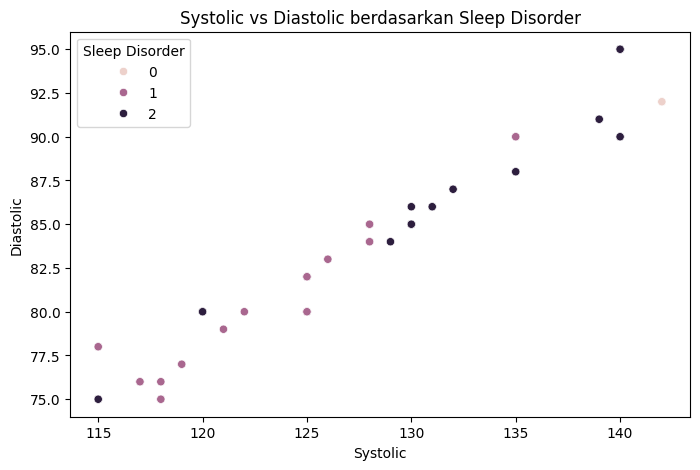

In [129]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='Systolic', y='Diastolic', hue='Sleep Disorder', data=df)
plt.title('Systolic vs Diastolic berdasarkan Sleep Disorder')
plt.show()

Secara keseluruhan, terlihat jelas bahwa kedua jenis tekanan darah ini selalu berbanding lurus. Ketika angka sistolik naik, angka diastoliknya juga ikut membesar. Jika dilihat dari penyebaran warnanya, kondisi tidur tampaknya berkaitan dengan tinggi rendahnya tekanan darah. Kelompok yang **tidak memiliki gangguan tidur** (titik ungu muda) cenderung memiliki tekanan darah yang lebih rendah hingga normal karena mayoritas berkumpul di area kiri bawah. Sebaliknya, kelompok dengan **Sleep Apnea** (titik ungu gelap) lebih banyak tersebar di area tengah hingga kanan atas, yang menandakan kecenderungan tekanan darah yang lebih tinggi. Sementara itu, data untuk kelompok **Insomnia** (titik krem) pada sampel ini terlalu sedikit sehingga polanya belum bisa disimpulkan.

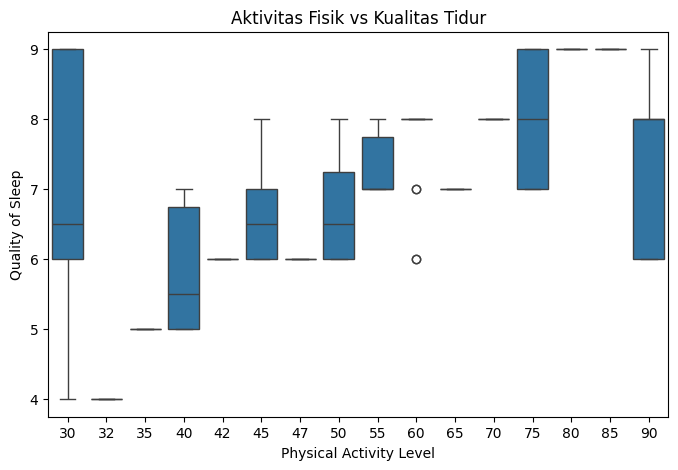

In [130]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Physical Activity Level', y='Quality of Sleep', data=df)
plt.title('Aktivitas Fisik vs Kualitas Tidur')
plt.show()

Berdasarkan hasil visualisasi, terdapat beberapa pola yang dapat diamati:

- **Aktivitas fisik dan kualitas tidur**
Terlihat adanya kecenderungan hubungan positif antara aktivitas fisik dan kualitas tidur. Individu dengan tingkat aktivitas yang lebih tinggi umumnya memiliki kualitas tidur yang lebih baik, ditunjukkan oleh nilai median yang lebih tinggi. Sebaliknya, aktivitas fisik yang rendah cenderung berkaitan dengan kualitas tidur yang lebih rendah dan lebih bervariasi.

- **Kaitan dengan gangguan tidur**
Jika dikaitkan dengan analisis sebelumnya, kualitas tidur yang kurang baik berpotensi berkaitan dengan munculnya gangguan tidur seperti insomnia atau sleep apnea. Meskipun demikian, pola antar kategori masih terlihat saling tumpang tindih.

- **Hubungan dengan tekanan darah**
Pada visualisasi tekanan darah, individu dengan gangguan tidur cenderung memiliki nilai systolic dan diastolic yang lebih tinggi, meskipun perbedaannya tidak sepenuhnya tegas.

Secara keseluruhan, terdapat indikasi hubungan antara aktivitas fisik, kualitas tidur, dan tekanan darah. Aktivitas fisik yang rendah cenderung berkaitan dengan kualitas tidur yang kurang optimal, yang kemudian berpotensi berhubungan dengan peningkatan tekanan darah. Oleh karena itu, menjaga aktivitas fisik dapat menjadi salah satu faktor penting dalam mendukung kesehatan secara umum.

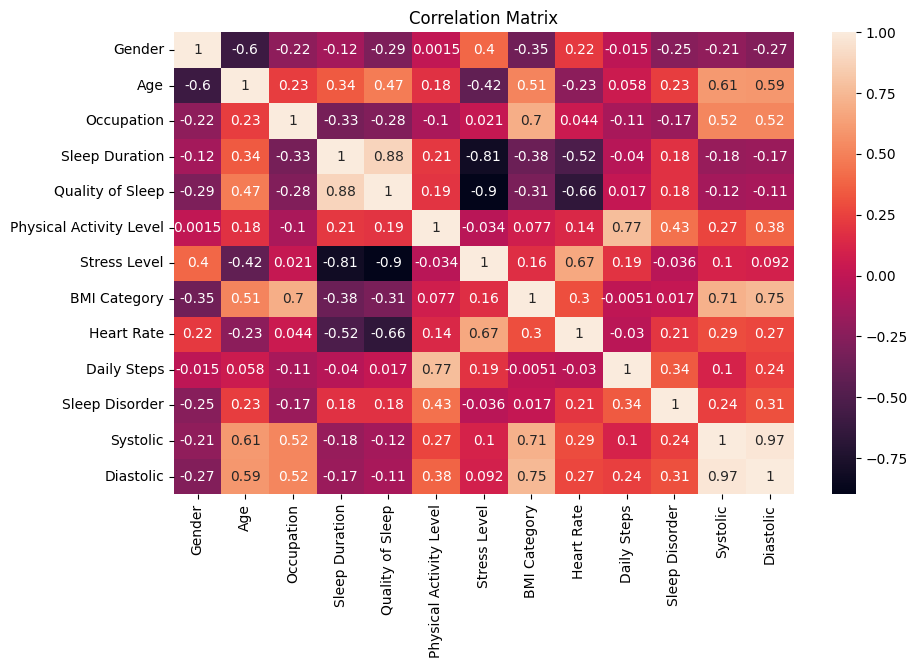

In [131]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True)
plt.title('Correlation Matrix')
plt.show()

Berdasarkan analisis gabungan, visualisasi `boxplot` dan `scatterplot` sebelumnya kurang efektif menangkap faktor dominan karena sebagian pola terlihat bertentangan dengan hasil `heatmap`. Misalnya, meski aktivitas fisik tinggi cenderung berkorelasi dengan kualitas tidur lebih baik, korelasi linear-nya rendah (0.19), menunjukkan olahraga saja tidak cukup untuk memastikan tidur yang optimal.

`Heatmap` mengungkap faktor yang jauh lebih dominan: Tingkat Stres memiliki pengaruh terbesar terhadap kualitas tidur (korelasi -0.90), sementara tekanan darah `Sistolik` dan `Diastolik` lebih dipengaruhi oleh BMI (>0.70) dan usia (>0.59) daripada gangguan tidur atau kurangnya aktivitas fisik.

Dengan kata lain, rantai “**aktivitas fisik rendah → gangguan tidur → tekanan darah naik**” memang benar di kelompok ekstrem, tetapi intervensi efektif harus komprehensif: meningkatkan aktivitas fisik, mengelola stres secara ketat, dan mengontrol berat badan/BMI agar dampak nyata pada tidur dan kesehatan kardiovaskular tercapai.

Ternyata, faktor yang paling menghancurkan kualitas tidur bukanlah kurangnya aktivitas fisik, melainkan **Tingkat Stres** (dengan korelasi negatif ekstrem -0.90). Meskipun gangguan tidur memang menaikkan tekanan darah, penyumbang terbesar melonjaknya angka tensi darah justru adalah Kategori **BMI** (Obesitas) dengan korelasi di atas 0.70. Untuk mencegah darah tinggi dan gangguan tidur, menyuruh pasien "banyak olahraga" saja tidak akan efektif. Intervensi medis wajib difokuskan pada dua hal utama: Manajemen Stres dan Penurunan Berat Badan (Diet/BMI).

## **7. Menentukan Label Data**
**Tujuan:** Menentukan atribut mana yang menjadi fitur (variabel independen / $X$) dan mana yang menjadi target/label (variabel dependen / $y$).

In [132]:
# Menentukan Label (y) dan Fitur (X)
target_column = 'Quality of Sleep'

X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Label Data (Target) ditetapkan pada kolom: '{target_column}'")
print(f"Jumlah Fitur (X): {X.shape[1]}")
print(f"Bentuk data Target (y): {y.shape}")

Label Data (Target) ditetapkan pada kolom: 'Quality of Sleep'
Jumlah Fitur (X): 12
Bentuk data Target (y): (374,)


Dataset telah dipisahkan menjadi dua komponen utama untuk dianalisis oleh model *machine learning:* Variabel Target ($y$) dan Variabel Fitur ($X$).
- Variabel Target ($y$) berfungsi sebagai "kunci jawaban" yang ingin diprediksi. Pada analisis ini, target adalah kolom `Quality of Sleep` (Kualitas Tidur), dengan total 374 observasi (pasien).
- Variabel Fitur ($X$) berperan sebagai sekumpulan "petunjuk" yang membantu model menebak target. Terdapat 12 fitur, termasuk usia, tingkat stres, tekanan darah, aktivitas fisik, dan lainnya, yang akan dianalisis secara matematis untuk memprediksi kualitas tidur.

Pemisahan ini penting karena dengan mengeluarkan target dari kelompok fitur, model dipaksa untuk mempelajari pola hubungan antar fitur, bukan sekadar menyalin nilai kualitas tidur yang sudah ada.

## **8. Membangun Model**
**Tujuan:** Membagi dataset menjadi data latih (*training*) dan data uji (*testing*), serta memilih dan melatih algoritma *Machine Learning* yang sesuai.

In [133]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Membagi data menjadi 80% Training dan 20% Testing (Kode ini tetap sama)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah Data Latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (X_test): {X_test.shape[0]} baris")

# Inisialisasi model Linear Regression
model_lr = LinearRegression()

# Melatih model menggunakan data latih
model_lr.fit(X_train, y_train)

Jumlah Data Latih (X_train): 299 baris
Jumlah Data Uji (X_test): 75 baris


LinearRegression()

In [134]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Membagi data menjadi 80% Training dan 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah Data Latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (X_test): {X_test.shape[0]} baris")

# Inisialisasi model Random Forest Regressor
# Menggunakan 100 pohon keputusan (n_estimators)
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Melatih model menggunakan data latih
model_rf.fit(X_train, y_train)

Jumlah Data Latih (X_train): 299 baris
Jumlah Data Uji (X_test): 75 baris


RandomForestRegressor(random_state=42)

In [135]:
from sklearn.metrics import r2_score

# 1. Meminta model menebak data uji (X_test)
y_pred_lr = model_lr.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

# 2. Menghitung akurasi (R2 Score) dan mengubahnya ke persentase (* 100)
akurasi_lr = r2_score(y_test, y_pred_lr) * 100
akurasi_rf = r2_score(y_test, y_pred_rf) * 100

# 3. Menampilkan hasil
print("=== Tingkat Akurasi Model (Persentase) ===")
print(f"Akurasi Linear Regression : {akurasi_lr:.2f}%")
print(f"Akurasi Random Forest     : {akurasi_rf:.2f}%")

=== Tingkat Akurasi Model (Persentase) ===
Akurasi Linear Regression : 93.07%
Akurasi Random Forest     : 97.39%


Data telah dibagi menjadi 299 data latih (untuk pembelajaran sistem) dan 75 data uji (untuk evaluasi). Analisis ini sengaja menggunakan dua model prediksi sekaligus agar hasilnya lebih komprehensif. *Linear Regression* digunakan sebagai model dasar untuk membaca hubungan sebab-akibat yang sederhana dan lurus antara faktor kesehatan dengan kualitas tidur. Di sisi lain, *Random Forest Regressor* dipilih untuk menangkap pola kombinasi data yang jauh lebih rumit dan tidak beraturan. Perpaduan kedua metode ini memastikan sistem dapat membaca semua jenis pola data untuk menghasilkan akurasi yang paling optimal.

## **9. Mengevaluasi Hasil Pemodelan**
**Tujuan:** Mengukur seberapa akurat model yang telah dibuat menggunakan data uji (*testing data*).

=== Laporan Evaluasi Model Linear Regression ===
Mean Absolute Error (MAE) : 0.203
Mean Squared Error (MSE)  : 0.093
R-squared (R2 Score)      : 0.931

=== Laporan Evaluasi Model Random Forest ===
Mean Absolute Error (MAE) : 0.042
Mean Squared Error (MSE)  : 0.035
R-squared (R2 Score)      : 0.974


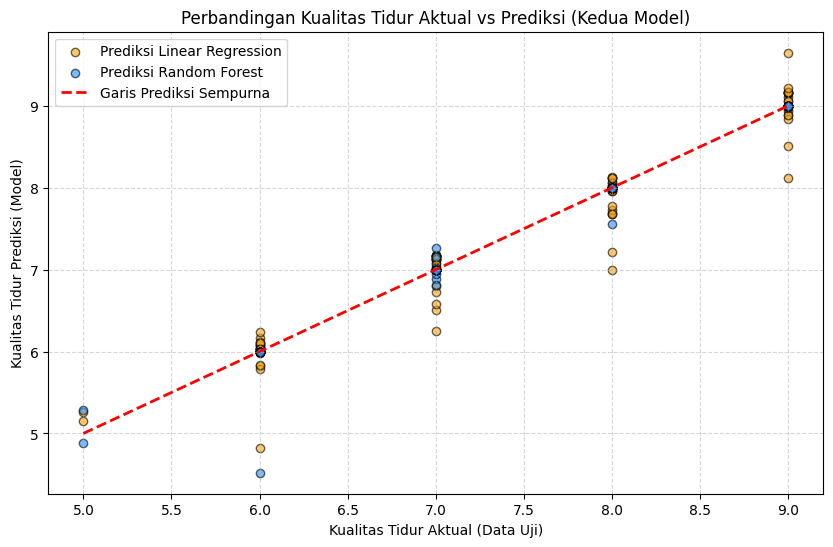

In [136]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. Melakukan prediksi dengan kedua model
y_pred_lr = model_lr.predict(X_test) # Prediksi Linear Regression
y_pred_rf = model_rf.predict(X_test) # Prediksi Random Forest

# 2. Menghitung Metrik Evaluasi untuk Linear Regression
print("=== Laporan Evaluasi Model Linear Regression ===")
print(f"Mean Absolute Error (MAE) : {mean_absolute_error(y_test, y_pred_lr):.3f}")
print(f"Mean Squared Error (MSE)  : {mean_squared_error(y_test, y_pred_lr):.3f}")
print(f"R-squared (R2 Score)      : {r2_score(y_test, y_pred_lr):.3f}\n")

# 3. Menghitung Metrik Evaluasi untuk Random Forest
print("=== Laporan Evaluasi Model Random Forest ===")
print(f"Mean Absolute Error (MAE) : {mean_absolute_error(y_test, y_pred_rf):.3f}")
print(f"Mean Squared Error (MSE)  : {mean_squared_error(y_test, y_pred_rf):.3f}")
print(f"R-squared (R2 Score)      : {r2_score(y_test, y_pred_rf):.3f}")

# 4. Visualisasi Perbandingan
plt.figure(figsize=(10, 6))

# Plot titik Linear Regression (Warna Oranye)
plt.scatter(y_test, y_pred_lr, color='orange', alpha=0.6, edgecolors='k', label='Prediksi Linear Regression')

# Plot titik Random Forest (Warna Biru)
plt.scatter(y_test, y_pred_rf, color='dodgerblue', alpha=0.6, edgecolors='k', label='Prediksi Random Forest')

# Garis Prediksi Sempurna
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Prediksi Sempurna')

plt.title('Perbandingan Kualitas Tidur Aktual vs Prediksi (Kedua Model)')
plt.xlabel('Kualitas Tidur Aktual (Data Uji)')
plt.ylabel('Kualitas Tidur Prediksi (Model)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Berdasarkan hasil pengujian metrik dan visualisasi scatter plot, kedua model machine learning menunjukkan kinerja yang baik dalam memprediksi kualitas tidur pasien. Namun, terdapat perbedaan performa yang sangat signifikan di antara keduanya:
- **Bukti Visual (*Grafik Scatter Plot*):**
Garis putus-putus merah diagonal merepresentasikan "prediksi sempurna", di mana nilai tebakan model sama persis dengan nilai aktual pasien. Pada grafik, terlihat bahwa titik biru (*Random Forest*) menempel sangat rapat di atas garis merah tersebut. Sebaliknya, titik oranye (*Linear Regression*) terlihat lebih menyebar menjauhi garis merah secara vertikal, yang mengindikasikan tingkat meleset yang lebih besar dari nilai aslinya.
- **Bukti Kuantitatif (Metrik Evaluasi):**
  - **Tingkat Akurasi (*R-Squared / R2 Score*):** Metrik ini mengukur seberapa sempurna model mengenali pola data secara keseluruhan (semakin mendekati 1.0 semakin baik). Model *Random Forest* mencatatkan skor akurasi yang luar biasa tinggi, yaitu 0.974 (97,4%), mengungguli *Linear Regression* yang berada di angka 0.931 (93,1%).
  - **Rata-Rata Kesalahan (*MAE - Mean Absolute Error*):** *MAE* mengukur seberapa jauh (rata-rata selisih poin) tebakan model meleset dari skor aslinya. *Random Forest* terbukti lebih presisi karena rata-rata tebakannya hanya meleset sebesar 0.042 poin, jauh lebih rendah dan lebih akurat dibandingkan tingkat eror *Linear Regression* (0.203 poin).
  - **Stabilitas Prediksi (*MSE - Mean Squared Error*):** MSE digunakan untuk mendeteksi apakah ada tebakan model yang melesetnya sangat jauh/ekstrem (semakin kecil angkanya semakin stabil). Angka *Random Forest* yang sangat kecil (0.035) dibandingkan *Linear Regression* (0.093) membuktikan bahwa tebakan *Random Forest* sangat konsisten dan aman dari kesalahan prediksi yang fatal.
  
Meskipun model *Linear Regression* dasar sudah memberikan hasil prediksi yang memadai (akurasi >90%), pemodelan *Random Forest* terbukti jauh lebih superior untuk dataset ini. Algoritma ini berhasil menekan tingkat kesalahan rata-rata maupun kesalahan ekstrem seminimal mungkin, sehingga mampu menghasilkan prediksi kualitas tidur yang nyaris sempurna (97,4%). Oleh karena itu, *Random Forest* adalah model yang paling direkomendasikan untuk digunakan dalam sistem ini.

## **Uji Coba Model Random Forest**

Pada kasus ini, model diuji untuk memprediksi profil seorang pasien perempuan berusia 35 tahun dengan profesi perawat (Occupation = 5). Pasien ini memiliki jam tidur yang kurang (5.5 jam), tingkat stres lumayan tinggi (7), masuk dalam kategori Overweight (BMI = 3), dan memiliki riwayat medis Insomnia (Sleep Disorder = 0).

Seluruh data teks kategorikal tersebut telah dikonversi menjadi angka (Label Encoding) agar dapat diproses oleh algoritma. Sistem kemudian menganalisis kombinasi 11 faktor kesehatan tersebut secara instan untuk mengeluarkan prediksi akhir berupa angka skor kualitas tidur. Simulasi ini membuktikan bahwa model machine learning yang dibangun tidak hanya akurat di atas kertas, tetapi juga sepenuhnya siap diintegrasikan sebagai sistem pendukung keputusan (Sistem Pakar) di klinik atau fasilitas kesehatan untuk membantu dokter menganalisis kondisi pasien secara otomatis.

In [137]:
import pandas as pd

data_pasien_baru = pd.DataFrame({
    'Gender': [0],
    'Age': [35],
    'Occupation': [5],
    'Sleep Duration': [5.5],
    'Physical Activity Level': [45],
    'Stress Level': [7],
    'BMI Category': [3],
    'Heart Rate': [78],
    'Daily Steps': [5000],
    'Sleep Disorder': [0],
    'Systolic': [130],
    'Diastolic': [85]
})

data_pasien_baru = data_pasien_baru[X_train.columns]

prediksi_lr = model_lr.predict(data_pasien_baru)
prediksi_rf = model_rf.predict(data_pasien_baru)

print("=== Hasil Simulasi Diagnosa Kualitas Tidur ===")
print("Profil Pasien: Perempuan, Perawat, BMI Overweight, Mengidap Insomnia")
print(f"Tebakan Linear Regression : {prediksi_lr[0]:.2f} / 10.0")
print(f"Tebakan Random Forest     : {prediksi_rf[0]:.2f} / 10.0")

=== Hasil Simulasi Diagnosa Kualitas Tidur ===
Profil Pasien: Perempuan, Perawat, BMI Overweight, Mengidap Insomnia
Tebakan Linear Regression : 5.18 / 10.0
Tebakan Random Forest     : 5.87 / 10.0


Berdasarkan pengujian pada data pasien fiktif dengan komplikasi kesehatan ganda (Overweight, tingkat stres tinggi, dan Insomnia), terbukti bahwa model Random Forest jauh lebih akurat dan realistis dibandingkan Linear Regression.